All the sequences data were retrived from NCBI as of 2026-02-26

In [3]:
import pandas as pd
from Bio import SeqIO, Entrez
from Bio.Seq import Seq 
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
mpl.rcParams['svg.fonttype'] = 'none'
# Path to your Arial.ttf file
# arial_font_path = '/home/skawakubo/fonts/Arial.ttf'
# Create a FontProperties object for the Arial font
# arial_font = FontProperties(fname=arial_font_path)
# mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time
import subprocess

In [4]:
def fasta_to_dataframe(fasta_file):
    ids = []
    sequences = []
    for record in SeqIO.parse(fasta_file, "fasta"):
        ids.append(record.id)
        sequences.append(str(record.seq))

    df = pd.DataFrame({
        "ID": ids,
        "seq": sequences
    })
    return df

In [8]:
# Read the fasta file　blastでhitした全配列のfasta
FCoV1_S_NCBI_seq_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV1_candidate_NCBI_Spike_mafft.fasta'
FCoV1_S_NCBI_seq = fasta_to_dataframe(FCoV1_S_NCBI_seq_path)
FCoV1_S_NCBI_seq.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_S_NCBI_seq

,Accession,seq
0,MW815651.1,at-ga--------------------tagttttactacttg------...
1,MW815661.1,at-ga--------------------tagtgttactacttg------...
2,MW815662.1,at-ga--------------------tactgttaatattag------...
3,MW316833.1,at-ga--------------------tgttgatgatatttg------...
4,PP908788.1,at-ga--------------------tagtgttactacttg------...
...,...,...
7555,MK574043.1,gt--------------------------------------------...
7556,MK574042.1,gt--------------------------------------------...
7557,MK217373.1,gt--------------------------------------------...
7558,KF663559.1,gt--------------------------------------------...


In [9]:
# Read the metadata　blastでhitした全配列のmeta
FCoV1_S_NCBI_meta_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV1_S_metadata_20260226.tsv'
FCoV1_S_NCBI_meta = pd.read_csv(FCoV1_S_NCBI_meta_path, sep="\t")
FCoV1_S_NCBI_meta

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date
0,OP433735.1,Porcine epidemic diarrhea virus,S-GDXF,taxon:28295,NaN,4161,NaN,NaN,porcine,NaN,04-Jun-2021,18-APR-2023
1,ON263410.1,Porcine epidemic diarrhea virus,GNU-1809,taxon:28295,NaN,4161,NaN,NaN,pig,NaN,2018,23-NOV-2022
2,KU133256.1,Porcine epidemic diarrhea virus,CH-SDQF-1-2014,taxon:28295,NaN,4152,NaN,NaN,swine,NaN,06-Mar-2014,29-MAR-2016
3,MT797682.1,Human coronavirus 229E,HK05-07,taxon:11137,NaN,3513,NaN,NaN,Homo sapiens,nasopharyngeal swab,2005-11,02-FEB-2021
4,KM975825.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,2214,NaN,NaN,pig,NaN,13-Feb-2014,09-JUL-2016
...,...,...,...,...,...,...,...,...,...,...,...,...
7555,ON554136.1,Human coronavirus 229E,HCoV-229E/BIME389-70/2019,taxon:11137,NaN,27237,NaN,NaN,Homo sapiens,NaN,2019,14-JUN-2023
7556,MZ703022.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,1128,NaN,NaN,pig,intestinal contents,Jan-2021,06-NOV-2022
7557,PP460571.1,Porcine epidemic diarrhea virus,PEDV-GXGG01-2023,taxon:28295,NaN,2376,NaN,NaN,porcine,NaN,2023,18-SEP-2024
7558,KJ645683.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,27998,NaN,NaN,porcine,feces,08-Dec-2013,17-JUN-2015


In [10]:
# Merge the metadata and the sequence
FCoV1_S_NCBI = pd.merge(FCoV1_S_NCBI_meta, FCoV1_S_NCBI_seq, on="Accession")
FCoV1_S_NCBI

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,seq
0,OP433735.1,Porcine epidemic diarrhea virus,S-GDXF,taxon:28295,NaN,4161,NaN,NaN,porcine,NaN,04-Jun-2021,18-APR-2023,at-ga---------------------------agtcttta------...
1,ON263410.1,Porcine epidemic diarrhea virus,GNU-1809,taxon:28295,NaN,4161,NaN,NaN,pig,NaN,2018,23-NOV-2022,at-ga---------------------------agtcttta------...
2,KU133256.1,Porcine epidemic diarrhea virus,CH-SDQF-1-2014,taxon:28295,NaN,4152,NaN,NaN,swine,NaN,06-Mar-2014,29-MAR-2016,at-ga---------------------------ggtcttta------...
3,MT797682.1,Human coronavirus 229E,HK05-07,taxon:11137,NaN,3513,NaN,NaN,Homo sapiens,nasopharyngeal swab,2005-11,02-FEB-2021,---------------------------------atgtttgt-----...
4,KM975825.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,2214,NaN,NaN,pig,NaN,13-Feb-2014,09-JUL-2016,at-ga---------------------------agtcttta------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7555,ON554136.1,Human coronavirus 229E,HCoV-229E/BIME389-70/2019,taxon:11137,NaN,27237,NaN,NaN,Homo sapiens,NaN,2019,14-JUN-2023,at-aa---------------------------aatgtttgt-----...
7556,MZ703022.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,1128,NaN,NaN,pig,intestinal contents,Jan-2021,06-NOV-2022,at-ga---------------------------agtcttta------...
7557,PP460571.1,Porcine epidemic diarrhea virus,PEDV-GXGG01-2023,taxon:28295,NaN,2376,NaN,NaN,porcine,NaN,2023,18-SEP-2024,at-ga---------------------------agtcttta------...
7558,KJ645683.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,27998,NaN,NaN,porcine,feces,08-Dec-2013,17-JUN-2015,at-ga---------------------------agtcttta------...


In [11]:
# FCoV_type1_spike_nt.fastaをクエリーにntblastをかけて取得した全配列の系統樹に基づいたFCoV cladeのlist
FCoV1_relatives_Spike_list = ['MT551867.1','MT551869.1','MT551868.1','KF312726.1','MF536801.1','JX035857.1','KF668591.1','JX035837.1','JX035844.1','JX035860.1','JX035838.1','MK986769.1','MK986779.1','MK986778.1','MK986780.1','MK986771.1','MG892440.1','MW858276.1','PQ561644.1','OQ565730.1','OQ565729.1','MT250371.1','PQ626040.1','MG560053.1','KM213244.1','KM213246.1','KM213247.1','MG560052.1','KM213248.1','KM213249.1','MZ221045.1','MZ221042.1','MZ221036.1','MZ221041.1','MZ221046.1','MZ221038.1','PQ565823.1','PQ565822.1','ON595883.1','ON595884.1','ON595877.1','ON595874.1','ON595878.1','ON595880.1','ON595881.1','MT250365.1','MT606060.1','MT606057.1','MT606100.1','MT606095.1','MT606050.1','MT606056.1','MT606098.1','MT606072.1','MT606085.1','MT606054.1','MT606075.1','MT606018.1','MT606074.1','MT606082.1','MT606040.1','MT606091.1','MT606070.1','MT606039.1','MT606079.1','MT606080.1','MT606090.1','MT606052.1','MT606049.1','MT606027.1','MT606032.1','MT606061.1','MT606048.1','MT606046.1','MT606037.1','MT606034.1','MT606044.1','MT606022.1','MT606031.1','MT606024.1','MT606062.1','MT606071.1','MT606089.1','MT606059.1','MT606033.1','MT606076.1','MT606068.1','MT606023.1','MT606097.1','MT606081.1','MT606077.1','MT606073.1','MT606051.1','MT606026.1','MT606019.1','MT606092.1','MT606047.1','MT606053.1','MT606078.1','MT606036.1','MT606088.1','MT606063.1','MT606084.1','MT606087.1','MT606035.1','MT606028.1','MT606067.1','MT606038.1','MT606093.1','MT606029.1','MT606020.1','MT606083.1','MT606045.1','MT606041.1','MT606058.1','MT606101.1','MT606099.1','MT606103.1','MT606102.1','DQ256137.1','AF533351.1','LC671470.1','LC671468.1','JQ304361.1','JQ304375.1','JQ304372.1','JQ304371.1','JQ304373.1','JQ304374.1','PP601332.1','JQ304430.1','JQ304424.1','JQ304422.1','JQ304420.1','JQ304426.1','JQ304423.1','MT250361.1','PP901887.1','JQ304392.1','JQ304489.1','JQ304459.1','JQ304394.1','JQ304318.1','JQ304314.1','JQ304481.1','JQ304297.1','JQ304440.1','JQ304448.1','JQ304434.1','JQ304390.1','JQ304307.1','JQ304509.1','PP901888.1','PP601331.1','PP601333.1','PP601322.1','PP601324.1','PP601323.1','JQ304445.1','JQ304446.1','MW225991.1','MW225967.1','PP901890.1','MZ081383.1','PP601330.1','MW225959.1','MW225990.1','JQ304393.1','JQ304396.1','JQ304316.1','JQ304503.1','JQ304485.1','JQ304295.1','JQ304498.1','PP601319.1','PP601328.1','JQ304433.1','JQ304336.1','JQ304455.1','JQ304325.1','JQ304326.1','JQ304335.1','JQ304354.1','JQ304356.1','JQ304353.1','JQ304357.1','JQ304359.1','JQ304358.1','JQ304383.1','MW225992.1','JQ304317.1','MZ711360.1','MK989624.1','MK989621.1','MK989620.1','PP601320.1','PP601321.1','PP601325.1','PP601326.1','JQ304474.1','JQ304437.1','JQ304300.1','JQ304402.1','JQ304403.1','JQ304507.1','JQ304502.1','JQ304438.1','JQ304302.1','JQ304466.1','JQ304379.1','JQ304303.1','JQ304363.1','JQ304366.1','JQ304431.1','JQ304341.1','JQ304340.1','JQ304311.1','JQ304365.1','PQ626037.1','MF357039.1','JQ304296.1','JQ304486.1','JQ304405.1','JQ304404.1','JQ304444.1','JQ304401.1','JQ304395.1','JQ304391.1','JQ304510.1','JQ304482.1','JQ304312.1','JQ304389.1','JQ304477.1','JQ304476.1','JQ304499.1','JQ304471.1','JQ304355.1','JQ304517.1','JQ304376.1','JQ304469.1','JQ304518.1','MW225969.1','MW225958.1','JQ304299.1','JQ304484.1','JQ304519.1','JQ304480.1','JQ304397.1','JQ304399.1','JQ304400.1','JQ304398.1','JQ304313.1','JQ304329.1','JQ304473.1','JQ304304.1','JQ304294.1','PP901886.1','JQ304364.1','JQ304362.1','JQ304301.1','JQ304520.1','AY159761.1','JQ304442.1','JQ304447.1','JQ304386.1','JQ304384.1','JQ304382.1','MW225984.1','JQ304470.1','OQ594072.1','JQ304435.1','JQ304330.1','JQ304334.1','MW225986.1','JQ304368.1','JQ304487.1','JQ304333.1','JQ304441.1','JQ304331.1','JQ304456.1','JQ304513.1','JQ304493.1','JQ304428.1','JQ304427.1','JQ304453.1','JQ304348.1','JQ304345.1','JQ304346.1','JQ304347.1','JQ304344.1','JQ304418.1','JQ304419.1','JQ304416.1','JQ304415.1','JQ304417.1','JQ304514.1','MW225966.1','JQ304515.1','JQ304497.1','JQ304429.1','JQ304380.1','JQ304370.1','JQ304369.1','JQ304501.1','JQ304500.1','JQ304464.1','JQ304328.1','JQ304327.1','JQ304406.1','JQ304407.1','JQ304412.1','JQ304411.1','JQ304409.1','JQ304408.1','JQ304410.1','JQ304488.1','JQ304319.1','MW225985.1','JQ304414.1','JQ304413.1','JQ304425.1','JQ304457.1','JQ304439.1','MW225987.1','JQ304454.1','MW225968.1','MW225974.1','MW225970.1','MW225971.1','MW225976.1','MW225978.1','JQ304322.1','JQ304495.1','JQ304305.1','JQ304504.1','JQ304306.1','JQ304505.1','MT250348.1','JQ304512.1','MW225962.1','JQ304432.1','MW858301.1','JQ304494.1','JQ304506.1','MT250347.1','JQ304443.1','JQ304388.1','JQ304492.1','JQ304387.1','MW225983.1','JQ304478.1','MF357046.1','MW225964.1','JQ304458.1','JQ304323.1','JQ304315.1','JQ304483.1','JQ304381.1','JQ304352.1','JQ304450.1','JQ304462.1','JQ304460.1','JQ304461.1','JQ304451.1','JQ304479.1','MW225965.1','JQ304338.1','JQ304337.1','JQ304516.1','MW225980.1','MW225979.1','JQ304465.1','JQ304298.1','JQ304320.1','PQ561612.1','PQ561613.1','PQ561611.1','JQ304467.1','JQ304452.1','MW225961.1','JQ304472.1','MT250373.1','MT250375.1','JQ304511.1','JQ304321.1','JQ304309.1','JQ304332.1','JQ304377.1','JQ304349.1','JQ304351.1','JQ304350.1','GU324419.1','LC753476.1','FJ917527.1','LC753477.1','KF312724.1','LC753475.1','KF312728.1','OQ974949.1','OP597274.1','AY307020.1','AY170345.1','OP422910.1','OP422909.1','OK340205.1','OK340204.1','OK340206.1','KT222995.1','MH603132.2','MK986768.1','KP849472.1','AY307021.1','MZ474760.1','MZ474765.1','MZ474791.1','MZ474773.1','MZ474772.1','MZ474793.1','MZ474770.1','MZ474767.1','OP422911.1','OP422906.1','KF312718.1','KP322041.1','KF312719.1','KF312720.1','EU664201.1','EF407993.1','MT250797.1','MT250798.1','MT250796.1','OP422913.1','KF312723.1','HG325838.1','HG325839.1','MT250374.1','MT250367.1','OP422915.1','MT250364.1','PQ641434.1','PQ641432.1','HF954953.1','HF954933.1','HF954930.1','HF954951.1','HF954958.1','HF954959.1','HF954932.1','HF954966.1','HF954957.1','HF954969.1','HF954968.1','PQ641443.1','HF954975.1','HF954974.1','HF954972.1','OP422912.1','MK986787.1','MK986782.1','OP422907.1','MK986770.1','JQ304385.1','OP422908.1','MT250354.1','MT250362.1','MT250366.1','MT250355.1','MT250358.1','MT250360.1','MT250359.1','MT250356.1','PQ641436.1','AF533347.1','HF954964.1','AF533342.1','AF533344.1','HF954949.1','AF533341.1','AF533339.1','HF954934.1','AF533338.1','PQ641430.1','HF954971.1','HF954935.1','AF533348.1','HF954970.1','HF954938.1','HF954936.1','HF954929.1','HF954931.1','HF954942.1','PQ641435.1','OK236314.1','PQ641441.1','OK236318.1','LC671496.1','LC671504.1','OK236333.1','MT294707.1','OK236270.1','HF954948.1','PQ641440.1','PQ641437.1','PQ641442.1','HF954962.1','HF954943.1','HF954927.1','MW225960.1','HF954950.1','MW225994.1','MW225993.1','MW225998.1','HF954956.1','HF954955.1','MF357050.1','MW225989.1','MF357045.1','MF357035.1','MF357038.1','MF357037.1','EU664284.1','EU664308.1','EU664298.1','EU664290.1','EU664288.1','EU664287.1','EU664279.1','EU664277.1','EU664314.1','EU664310.1','EU664285.1','EU664280.1','EU664291.1','EU664307.1','EU664292.1','EU664303.1','EU664295.1','PQ540759.1','MW858269.1','MG892399.1','MG892400.1','LC671493.1','LC671479.1','MG016697.1','LC671517.1','PQ479637.1','MW858270.1','PQ561635.1','PQ561628.1','PQ318091.1','PQ561641.1','PQ479635.1','PQ561620.1','PQ540765.1','PQ626036.1','PQ561629.1','PQ479638.1','MF357053.1','PQ626044.1','PQ561645.1','MG892421.1','PQ479636.1','PQ540758.1','PQ310513.1','PQ310512.1','MG892408.1','OQ196043.1','OQ196042.1','PQ561627.1','PQ626039.1','PQ626038.1','MF357048.1','HG325837.1','MF357043.1','MH292846.1','MF357042.1','MF357047.1','MF357044.1','PQ561614.1','OR948579.1','OR948575.1','OR948577.1','OR948578.1','HQ206649.1','JQ304360.1','MT551871.1','MT551870.1','JQ304508.1','PP601327.1','PP901884.1','PP901889.1','OQ407512.1','MT181982.1','MN049970.1','PV246290.1','OQ196082.1','OK236302.1','MG016696.1','MW316831.1','MW316832.1','PV246291.1','PP097360.1','OQ196053.1','OK236315.1','MW858320.1','MT444152.1','MW858292.1','MW858324.1','OR908445.1','PP097358.1','PP097359.1','OK236338.1','MG016686.1','MG016702.1','MG016688.1','PV246296.1','MW858308.1','KF530123.1','EU513383.1','MW858277.1','JN183882.1','MG016691.1','MG016690.1','OQ196085.1','OK236299.1','EU327719.1','EU327728.1','EU327729.1','EU327718.1','EU327704.1','EU327697.1','EU327706.1','EU327705.1','EU327701.1','EU327702.1','EU327700.1','EU327736.1','EU327749.1','EU327730.1','EU327732.1','EU327748.1','EU327747.1','EU327750.1','MW316839.1','MG016704.1','MG016692.1','MW858275.1','MW858327.1','MG892404.1','MG892412.1','MW858256.1','MW316842.1','OK236307.1','OQ196038.1','PP901872.1','EU327708.1','OK236259.1','MT112937.1','OQ407516.1','MW858267.1','PP908789.1','PQ540760.1','PQ540761.1','OQ594155.1','PP901878.1','KY566211.1','MG016701.1','KY566209.1','KY566210.1','MW858255.1','MW858278.1','MW858296.1','MG892417.1','OK236312.1','OQ407518.1','MW030108.1','MW858262.1','OQ407510.1','MG892426.1','MW858298.1','EU513382.1','MG016694.1','MW858328.1','MG892431.1','MG892402.1','OQ407517.1','OK236295.1','MW858266.1','OR141637.1','MW648557.1','MW648573.1','JQ422553.1','MK736790.1','JQ422552.1','OQ565714.1','OQ565732.1','MK736800.1','OR141615.1','JQ422563.1','OQ565716.1','JQ422558.1','OQ565715.1','OQ565731.1','OQ565724.1','OQ565727.1','JQ422565.1','JQ422556.1','JQ422551.1','JQ422562.1','JQ422561.1','JQ422557.1','JQ422560.1','JQ422554.1','OQ594175.1','OQ594077.1','OQ594143.1','OQ594156.1','OQ594127.1','MG892441.1','PV246288.1','MG016695.1','MW858252.1','OK236272.1','OK236330.1','OK236321.1','MW858318.1','OQ594100.1','PV246293.1','OK236309.1','EF408015.1','MW858305.1','OK236334.1','OQ196072.1','MW858319.1','MG016700.1','EU513384.1','OR141619.1','LC671461.1','LC671459.1','LC671512.1','LC671477.1','LC671478.1','LC671518.1','LC671520.1','LC671519.1','OQ196070.1','OK236303.1','OQ594141.1','OQ594137.1','OQ594063.1','MW030110.1','OK236306.1','OQ594131.1','OQ594193.1','OQ594149.1','PV246287.1','OQ196041.1','OQ594111.1','OQ594075.1','LC671460.1','OQ594047.1','MT181981.1','OQ594153.1','PV246294.1','MG892413.1','MG892425.1','PP097361.1','OQ196081.1','OQ196080.1','OQ196079.1','OQ196078.1','OQ594129.1','MT112944.1','MT112936.1','OQ594145.1','AY159781.1','AY159783.1','AY159756.1','MW815653.1','MW815654.1','MZ221043.1','MZ221039.1','MW815655.1','MZ221034.1','MZ221037.1','HQ206645.1','HF954965.1','PQ641431.1','HF954928.1','HF954963.1','HF954937.1','HF954946.1','HQ206648.1','MW815658.1','MW858259.1','OK236339.1','OK236305.1','MW316840.1','MW858309.1','OK236278.1','OK236277.1','OK236273.1','OK236261.1','OK236276.1','OQ196071.1','PV246309.1','MG016689.1','OK236313.1','OQ196056.1','OQ196057.1','OQ196058.1','MW316841.1','OQ196055.1','MW316844.1','KJ665871.1','EU327733.1','KJ665869.1','KJ665870.1','KJ665878.1','KJ665880.1','MW858286.1','MG892447.1','MG892460.1','MG892418.1','OQ351917.1','OQ407522.1','MW858290.1','MG892461.1','MW858283.1','MW858261.1','MW858273.1','MG016706.1','MG892416.1','MW815650.1','OK236298.1','OQ594173.1','OQ594152.1','JQ304308.1','MT112935.1','MG892432.1','MN165107.1','MG892439.1','OQ594207.1','DQ256138.1','MK736783.1','ON597862.1','MW316845.1','OQ594083.1','OQ594093.1','OQ594195.1','PQ479639.1','MW225988.1','MT250363.1','MT250370.1','PQ561616.1','OQ594085.1','MT181986.1','OQ594098.1','MW858291.1','OQ594060.1','MW815656.1','MW858313.1','PV246289.1','OK236296.1','OQ594051.1','OQ407511.1','MT181985.1','OQ594106.1','OQ594150.1','LC671499.1','KX722531.1','MW858260.1','OQ594185.1','MT181984.1','MT250378.1','MW648584.1','OQ351918.1','OQ407523.1','MW858271.1','KY292377.1','MG016687.1','OQ407521.1','OK236322.1','OQ407513.1','MK736793.1','MW316838.1','OQ196092.1','PP601334.1','OQ594202.1','OQ594112.1','OQ594091.1','OQ594148.1','OQ594101.1','OQ594134.1','MT181983.1','MT166690.1','OQ594082.1','OQ594154.1','OQ594136.1','MW815659.1','OQ594065.1','OQ594073.1','PQ540763.1','OQ196054.1','OK236275.1','OK236287.1','OK236260.1','OK236290.1','PP901879.1','MW858272.1','MG892437.1','MG892436.1','MG892435.1','PP254210.1','PP254211.1','PP254209.1','OQ594177.1','PP254213.1','PP254215.1','PP254206.1','PP254214.1','PP254212.1','PP254208.1','MG892395.1','MG892452.1','MW858263.1','PV246310.1','MT250353.1','MW858314.1','KP143508.1','KP143507.1','KP143512.1','OQ196073.1','OQ196076.1','OQ196075.1','OQ196074.1','DQ848678.1','AY159754.1','OQ196059.1','OQ196061.1','OQ196060.1','OQ196065.1','OQ196064.1','OQ196063.1','OQ196062.1','MW858287.1','MG892398.1','MW316836.1','MW858321.1','OK236300.1','LC671473.1','MG892458.1','PV246295.1','MW858293.1','MW316830.1','MG892396.1','MW815662.1','MG892446.1','OQ196069.1','OQ196068.1','OK236304.1','MW858322.1','OQ196066.1','MG016698.1','LC671486.1','LC671485.1','MW858294.1','FJ938053.1','FJ938054.1','OQ196046.1','OQ196045.1','OQ196044.1','OQ196052.1','OQ196051.1','OQ196050.1','OQ196049.1','OQ196048.1','OQ196047.1','FJ938062.1','FJ938055.1','FJ938059.1','FJ938052.1','OQ594121.1','PP901882.1','MT250349.1','OQ594162.1','OQ594179.1','PQ561634.1','OQ594115.1','OQ594199.1','OQ594170.1','OQ594168.1','OQ594054.1','OQ594206.1','JQ304449.1','OQ594071.1','MT250372.1','MT250352.1','OQ594062.1','OQ594070.1','MT112945.1','MT112946.1','OQ594099.1','OQ594125.1','OQ594108.1','MW316833.1','MW858295.1','OQ594146.1','MW225957.1','OQ594140.1','OQ594174.1','OQ594176.1','OQ594164.1','OQ594163.1','OQ594208.1','OQ594110.1','OQ594187.1','OQ594088.1','PQ540767.1','PQ540766.1','PQ626043.1','PQ626042.1','OQ594058.1','OQ594055.1','OQ594189.1','OQ594190.1','KJ665867.1','KJ665868.1','EU327707.1','EU327720.1','OQ594135.1','OQ594068.1','OQ594133.1','PP908790.1','OQ594201.1','OQ594204.1','MT239440.1','OQ594074.1','OQ594126.1','OQ594081.1','OQ594061.1','OQ594114.1','OQ594157.1','PP901885.1','KX722529.1','OQ594144.1','OQ594050.1','OQ594186.1','MW316834.1','MW858279.1','MT166691.1','OQ594209.1','OQ594142.1','MF357051.1','MF357036.1','ON597863.1','MW316843.1','OQ407514.1','OQ594086.1','OQ594049.1','OK236285.1','LC671497.1','ON595858.1','OR141611.1','OK236337.1','OK236311.1','OK236328.1','OK236327.1','OQ196088.1','MW316835.1','MW858315.1','MW858326.1','OQ196087.1','MW858317.1','MW858300.1','MW815661.1','MG892462.1','MG892442.1','PP901877.1','OQ196090.1','OK236301.1','MW858264.1','PP908788.1','PP901873.1','EU327711.1','LC671467.1','EU327734.1','EU327699.1','MT166689.1','MT166688.1','MT166687.1','MF357041.1','MW858253.1','MW648581.1','PV246323.1','OK236336.1','MW858307.1','OK236343.1','OK236340.1','MG016707.1','PP901871.1','OQ594203.1','PP901880.1','OQ594158.1','OQ594052.1','PP901883.1','OQ594078.1','OQ594117.1','OQ594090.1','HQ206647.1','HQ206644.1','PQ561626.1','PP901876.1','OQ594128.1','OQ594124.1','OQ594123.1','OQ594130.1','OQ594104.1','OQ594069.1','OQ594132.1','OQ594116.1','OQ594139.1','OQ594056.1','OQ594084.1','OQ594188.1','MT250376.1','JQ304463.1','OQ594159.1','OQ594109.1','OQ594171.1','OQ594200.1','OQ594076.1','PP901874.1','OR141627.1','OR141626.1','OQ594165.1','MW308128.1','KJ665877.1','KJ665881.1','KJ665876.1','OQ594067.1','OQ594151.1','MW225963.1','OQ594147.1','OQ594183.1','OQ594192.1','OQ594097.1','OQ594172.1','MT181987.1','OQ594080.1','MT250350.1','MN049968.1','MT250351.1','OQ594057.1','OQ594064.1','OQ594107.1','MG892454.1','PQ626041.1','PQ561636.1','PQ561617.1','PQ561618.1','MG892450.1','PQ561639.1','JQ304378.1','OR141610.1','MW316847.1','JQ304324.1','OQ594138.1','MW225981.1','HG325840.1','PP601329.1','MZ221033.1','MW815652.1','PQ561615.1','PP601335.1','JQ304367.1','JQ304339.1','JQ304310.1','OQ594092.1','HQ829850.1','MW815660.1','HQ206646.1','HQ829851.1','HQ829849.1','HM628778.1','EU664305.1','EU664306.1','EU664297.1','EU664317.1','EU664289.1','AB644273.1','EU664282.1','EU664315.1','EU664309.1','EU664300.1','EU664299.1','EU664296.1','EU664293.1','EU664286.1','EU664276.1','MT250377.1','OK340213.1','MT250357.1','MG892424.1','MW858311.1','MW648560.1','MW648574.1','MK736788.1','OR141612.1','OR141633.1','MW648556.1','OR141641.1','MK736785.1','OR141613.1','MK736792.1','OR141639.1','MK736798.1','MK736796.1','MW648583.1','OR141636.1','OR141628.1','OR141620.1','OR141629.1','MW648554.1','MW648567.1','LC671511.1','LC671462.1','LC671492.1','LC671484.1','LC671476.1','LC671481.1','JN183883.1','MW316846.1','MW858254.1','PV246297.1','MG892403.1','MW858268.1','OQ196101.1','OQ196098.1','OK236320.1','MG892445.1','MG892433.1','MG892411.1','MG892434.1','OK236329.1','OK236319.1','MG892449.1','OK236323.1','PV246292.1','OK236269.1','OK236310.1','OK236292.1','MW858274.1','OQ196091.1','MG892397.1','MG892457.1','OK236294.1','LC671475.1','LC671491.1','PP254207.1','MG892414.1','OK236274.1','OK236335.1','OK236288.1','MW858285.1','PP901870.1','OQ407519.1','OK236324.1','OK236325.1','PV246283.1','OQ407515.1','MG892407.1','MG016685.1','KJ665862.1','KJ665866.1','MW225997.1','OQ196039.1','KJ665875.1','KJ665863.1','KJ665874.1','MG893511.1','PQ540757.1','MW858325.1','PQ626046.1','PQ561633.1','PQ561632.1','MF357040.1','MG892410.1','MG892409.1','MW815651.1','OQ594087.1','OQ594102.1','OQ594053.1','MW858258.1','MK736794.1','MW858303.1','MW858302.1','MG892444.1','MW858304.1','MG892453.1','LC671483.1','LC671488.1','OK236291.1','MK736789.1','LC671514.1','EU327709.1','EU327717.1','EU327721.1','ON595868.1','ON595866.1','ON595863.1','ON595875.1','ON595853.1','ON595867.1','ON595870.1','ON595854.1','ON595861.1','ON595860.1','ON595857.1','ON595859.1','ON595876.1','ON595862.1','ON595882.1','ON595879.1','MW648571.1','OR141624.1','MW648558.1','ON595864.1','ON595871.1','ON595869.1','ON595865.1','OR141625.1','AF533346.1','ON595856.1','ON595872.1','ON595873.1','MK736787.1','MK736803.1','OR141640.1','MW648553.1','LC671515.1','ON595855.1','OQ594105.1','OQ594210.1','OQ594211.1','MW858281.1','OQ594094.1','OQ594066.1','OQ594079.1','ON597860.1','OQ594167.1','OQ594166.1','OQ594196.1','HQ392470.1','HQ012367.1','AY159769.1','AY159737.1','AY159739.1','AY159749.1','AY159757.1','AY159751.1','AY159778.1','OQ594095.1','ON597861.1','OQ594089.1','OQ196067.1','OQ594122.1','OQ594096.1','KJ665872.1','EU664278.1','EU664302.1','EU664275.1','KX722530.1','MW858282.1','LC742526.1','MK736784.1','LC671472.1','EU327740.1','LC671495.1','MW815657.1','LC671464.1','JN654410.1','FJ938058.1','OQ196040.1','MW858265.1','MG892428.1','HQ012372.1','HQ012369.1','GU553361.1','GU553362.1','OQ594103.1','OQ594048.1','MW858316.1','MF457591.1','MG892438.1','MW858299.1','MW858306.1','MG892448.1','HQ012370.1','MK736804.1','DQ160294.1','EU513391.1','EU513390.1','EF408014.1','MW858310.1','MK736791.1','EF408013.1','MG892420.1','EU327723.1','MG892451.1','OK236331.1','LC671502.1','EU327752.1','EU327696.1','LC671505.1','LC671463.1','LC671501.1','AB535528.1','AB695067.1','D32044.1','EU664187.1','LC852817.1','LC671480.1','EF408012.1','LC671489.1','EF408010.1','EF408011.1','FJ917526.1','FJ943771.1','OP542206.1','MW316837.1','FJ917524.1','FJ943764.1','FJ943761.1','FJ917523.1','FJ943767.1','FJ943765.1','FJ917522.1','FJ917521.1','FJ917519.1','FJ917530.1','FJ917520.1','FJ917534.1','FJ917535.1','FJ917531.1','FJ917533.1','FJ917532.1','PQ561647.1','PQ561623.1','PQ561622.1','PQ561625.1','MW858257.1','PQ561624.1','OQ594169.1','OQ594191.1','OQ594160.1','OQ594198.1','OQ594113.1','EF407997.1','EF407990.1','OQ407520.1','EF407992.1','EF407991.1','EF407994.1','EF407996.1','EF407995.1','EF407989.1','EF408021.1','EF407988.1','PQ561630.1','PQ561610.1','PQ561609.1','MG892464.1','MW858289.1','PQ540762.1','PQ561648.1','EU513381.1','PQ561619.1','PQ561643.1','PQ540769.1','PQ540768.1','PQ561642.1','PQ540770.1','PQ626045.1','MW858312.1','PQ561638.1','PQ318089.1','PQ561646.1','EU327751.1','MG892443.1','PQ561649.1','PQ561631.1','PQ561640.1','PQ561637.1','PQ561621.1','PQ540764.1','MN049969.1','OQ196094.1','OQ196093.1','PP854701.1','PP067758.1','PP854702.1','PP067759.1','PP901881.1','MW648570.1','MG016699.1','MK736801.1','MH817484.1','MW648580.1','MW648555.1','MW648561.1','MW648577.1','OQ196089.1','HQ392471.1','FJ943762.1','JN654407.1','JN654405.1','JN654401.1','JN654402.1','JN654406.1','JN654408.1','JN654403.1','JN654409.1','JN654404.1','OR141635.1','FJ938051.1','OQ196084.1','OQ196083.1','OQ196086.1','EF408016.1','EF407999.1','EF408017.1','HQ012368.1','FJ938057.1','FJ938056.1','MW858323.1','MW858288.1','FJ917529.1','FJ917528.1','HF954947.1','HF954952.1','HF954967.1','KJ665865.1','EU186072.1','KJ665873.1','DQ122858.1','AB088223.1','PP901875.1','AF533343.1','OQ196095.1','OQ196100.1','OQ196099.1','OQ196097.1','OQ196096.1','EU664316.1','EU664313.1','EU664312.1','EU664304.1','FJ943769.1','FJ917525.1','MT551827.1','MT551820.1','MT551818.1','AF533340.1','MT551828.1','MT551826.1','MT551825.1','MT551824.1','MT551823.1','MT551822.1','MT551821.1','MT551819.1','MT551816.1','MT551814.1','MT551813.1','MT551812.1','MT551811.1','MT551859.1','MT551858.1','MT551857.1','MT551856.1','MT551855.1','MT551854.1','MT551852.1','MT551851.1','EF408019.1','AB088222.1','OP597272.1','DQ256139.1','DQ256140.1','KU215428.1','KU215427.1','KU215419.1','KU215420.1','KU215425.1','KU215424.1','FJ938061.1','FJ938060.1','KU215423.1','KU215426.1','KU215422.1','KU215421.1','HQ392469.1','HQ012371.1','HQ392472.1','AY159771.1','AY159770.1','AY159765.1','LC671482.1','LC671465.1','LC671516.1','LC671498.1','AY159764.1','OK236316.1','EU664197.1','EU664188.1','EU664198.1','EU664200.1','EU664199.1','LC671466.1','AY159772.1','AY159768.1','EU327695.1','EU327698.1','EU327703.1','LC671471.1','EU664202.1','EU664186.1','EU664185.1','EU664184.1','MW648582.1','MG892430.1','MW858284.1','LC671469.1','LC671510.1','LC671508.1','LC671509.1','LC671500.1','LC671503.1','MG892405.1','EU664183.1','EU664180.1','EU664182.1','EU664211.1','EU664210.1','EU664209.1','EU664206.1','EU664205.1','EU664203.1','EU664208.1','LC671474.1','LC671507.1','MW648563.1','EF408018.1','AY159759.1','AY159775.1','AY159773.1','LC671494.1','MK736795.1','OR141617.1','EF407998.1','MK736797.1','EU327722.1','EU327746.1','EU327715.1','EU327716.1','OQ196077.1','AY159753.1','AY159780.1','AY159779.1','AY159743.1','AY159752.1','EU327739.1','LC671506.1','KF524853.1','EU327714.1','EU327712.1','EU327713.1','EU327731.1','EU327742.1','MG892422.1','MG892463.1','OK236293.1','EU327735.1','AY159747.1','AY159748.1','AY159746.1','AY159742.1','AY159741.1','AY159736.1','AY159740.1','AY159735.1','AY159774.1','AY159738.1','AY159750.1','AY159767.1','AY159766.1','OK236308.1','MW648575.1','OR141609.1','LC671490.1','OR141643.1','OR141630.1','OR141632.1','MW648565.1','MW648579.1','OQ565733.1','JQ422559.1','OQ565723.1','OQ565728.1','OQ565726.1','OQ565717.1','OQ565719.1','OQ565720.1','OQ565718.1']
len(FCoV1_relatives_Spike_list)

1715

In [12]:
# isin を用いてAccessionでseqを抽出
FCoV1_S = FCoV1_S_NCBI[FCoV1_S_NCBI['Accession'].isin(FCoV1_relatives_Spike_list)]
FCoV1_S

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,seq
21,JX035857.1,Canine coronavirus,16_typeI_3.7_UK_2007,taxon:11153,NaN,621,NaN,NaN,kennelled dog,NaN,2007,04-SEP-2012,----------------------------------------------...
22,EF408012.1,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,----------------------------------------------...
26,JQ304323.1,Feline coronavirus,FECV9,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,----------------------------------------------...
27,OK236292.1,Feline coronavirus,FIPV/HB/WH/2019/11/Runtu,taxon:12663,NaN,306,NaN,NaN,felis,fecal samples and seroperitoneum,2020,23-SEP-2022,----------------------------------------------...
32,JN654404.1,Feline coronavirus,NaN,taxon:12663,NaN,360,NaN,NaN,cat,feline fecal,Jun-2009,25-JUL-2016,----------------------------------------------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7544,FJ938055.1,Feline coronavirus UU8,NaN,taxon:627435,NaN,29285,NaN,NaN,cat,NaN,24-May-2007,11-JUL-2009,at-ga--------------------tgttgttaatacttg------...
7545,MW225970.1,Feline coronavirus,Aramis_feces,taxon:12663,NaN,189,NaN,NaN,Felis catus,feces,2019,18-JAN-2021,----------------------------------------------...
7549,EU664199.1,Feline coronavirus,4621fe,taxon:12663,NaN,225,NaN,NaN,NaN,Maryland catteries FIPV and FECV biotypes 2004...,NaN,26-JUL-2016,----------------------------------------------...
7553,EF408018.1,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,----------------------------------------------...


In [13]:
# 1. カラムを追加
FCoV1_S['biotype'] = None  # または初期値
FCoV1_S['Source'] = 'NCBI'

# 2. 列の順序を再定義
cols = ['Accession', 'biotype', 'Organism_Name', 'Isolate', 'Species', 'Genotype', 
        'Length', 'Geo_Location', 'Country', 'Host', 'Tissue_Specimen_Source', 
        'Collection_Date', 'Release_Date', 'Source', 'seq']
FCoV1_S = FCoV1_S.reindex(columns=cols)
FCoV1_S

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_46488/4275965587.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  FCoV1_S['biotype'] = None  # または初期値
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_46488/4275965587.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  FCoV1_S['Source'] = 'NCBI'


,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
21,JX035857.1,None,Canine coronavirus,16_typeI_3.7_UK_2007,taxon:11153,NaN,621,NaN,NaN,kennelled dog,NaN,2007,04-SEP-2012,NCBI,----------------------------------------------...
22,EF408012.1,None,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,NCBI,----------------------------------------------...
26,JQ304323.1,None,Feline coronavirus,FECV9,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
27,OK236292.1,None,Feline coronavirus,FIPV/HB/WH/2019/11/Runtu,taxon:12663,NaN,306,NaN,NaN,felis,fecal samples and seroperitoneum,2020,23-SEP-2022,NCBI,----------------------------------------------...
32,JN654404.1,None,Feline coronavirus,NaN,taxon:12663,NaN,360,NaN,NaN,cat,feline fecal,Jun-2009,25-JUL-2016,NCBI,----------------------------------------------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7544,FJ938055.1,None,Feline coronavirus UU8,NaN,taxon:627435,NaN,29285,NaN,NaN,cat,NaN,24-May-2007,11-JUL-2009,NCBI,at-ga--------------------tgttgttaatacttg------...
7545,MW225970.1,None,Feline coronavirus,Aramis_feces,taxon:12663,NaN,189,NaN,NaN,Felis catus,feces,2019,18-JAN-2021,NCBI,----------------------------------------------...
7549,EU664199.1,None,Feline coronavirus,4621fe,taxon:12663,NaN,225,NaN,NaN,NaN,Maryland catteries FIPV and FECV biotypes 2004...,NaN,26-JUL-2016,NCBI,----------------------------------------------...
7553,EF408018.1,None,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,NCBI,----------------------------------------------...


In [14]:
# 元データのコピーを作成
FCoV1_S_biotype = FCoV1_S.copy()

# 条件による更新
# case=False で大文字・小文字を無視
mask_fecv = FCoV1_S_biotype[['Organism_Name', 'Isolate']].apply(lambda x: x.str.contains('FECV', case=False, na=False)).any(axis=1)
mask_fipv = FCoV1_S_biotype[['Organism_Name', 'Isolate']].apply(lambda x: x.str.contains('FIP|feline infectious peritonitis', case=False, na=False, regex=True)).any(axis=1)

FCoV1_S_biotype.loc[mask_fecv, 'biotype'] = 'FECV'
FCoV1_S_biotype.loc[mask_fipv, 'biotype'] = 'FIPV'
FCoV1_S_biotype

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
21,JX035857.1,None,Canine coronavirus,16_typeI_3.7_UK_2007,taxon:11153,NaN,621,NaN,NaN,kennelled dog,NaN,2007,04-SEP-2012,NCBI,----------------------------------------------...
22,EF408012.1,None,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,NCBI,----------------------------------------------...
26,JQ304323.1,FECV,Feline coronavirus,FECV9,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
27,OK236292.1,FIPV,Feline coronavirus,FIPV/HB/WH/2019/11/Runtu,taxon:12663,NaN,306,NaN,NaN,felis,fecal samples and seroperitoneum,2020,23-SEP-2022,NCBI,----------------------------------------------...
32,JN654404.1,None,Feline coronavirus,NaN,taxon:12663,NaN,360,NaN,NaN,cat,feline fecal,Jun-2009,25-JUL-2016,NCBI,----------------------------------------------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7544,FJ938055.1,None,Feline coronavirus UU8,NaN,taxon:627435,NaN,29285,NaN,NaN,cat,NaN,24-May-2007,11-JUL-2009,NCBI,at-ga--------------------tgttgttaatacttg------...
7545,MW225970.1,None,Feline coronavirus,Aramis_feces,taxon:12663,NaN,189,NaN,NaN,Felis catus,feces,2019,18-JAN-2021,NCBI,----------------------------------------------...
7549,EU664199.1,None,Feline coronavirus,4621fe,taxon:12663,NaN,225,NaN,NaN,NaN,Maryland catteries FIPV and FECV biotypes 2004...,NaN,26-JUL-2016,NCBI,----------------------------------------------...
7553,EF408018.1,None,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,NCBI,----------------------------------------------...


In [11]:
print(FCoV1_S_biotype["biotype"].value_counts())

biotype
FIPV    221
FECV    134
Name: count, dtype: int64


In [15]:
# biotype が欠損値（NaN/None）でない行だけを抽出
FCoV1_S_biotype = FCoV1_S_biotype.dropna(subset=['biotype'])
FCoV1_S_biotype.reset_index(drop=True, inplace=True)
FCoV1_S_biotype

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
0,JQ304323.1,FECV,Feline coronavirus,FECV9,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
1,OK236292.1,FIPV,Feline coronavirus,FIPV/HB/WH/2019/11/Runtu,taxon:12663,NaN,306,NaN,NaN,felis,fecal samples and seroperitoneum,2020,23-SEP-2022,NCBI,----------------------------------------------...
2,JQ304336.1,FECV,Feline coronavirus,FECV179,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
3,JQ304435.1,FIPV,Feline coronavirus,fecesFIPV74,taxon:12663,NaN,474,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
4,JQ304371.1,FECV,Feline coronavirus,FECV418,taxon:12663,NaN,505,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
350,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,NaN,348,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
351,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI,----------------------------------------------...
352,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,NaN,360,NaN,NaN,Felis catus,ascites,NaN,04-FEB-2024,NCBI,----------------------------------------------...
353,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,NaN,543,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...


In [16]:
# select only the sequences with the length longer than 100
FCoV1_S_biotype_length = FCoV1_S_biotype[FCoV1_S_biotype['Length'] > 100]
FCoV1_S_biotype_length.reset_index(drop=True, inplace=True)
len(FCoV1_S_biotype_length)


338

In [17]:
# whole genome seqsがある配列に基づくアライメントからspikeの領域を抽出してきたファイル
# Read the fasta file 恐らくFCoV_relatives(Izumi and NCBIをcombineした25k以上のdataset)のSpike treeから抽出したtype1 FCoV clade(SeCoV含む)
FCoV1_S_Izumi_NCBI_seq_path = '/Users/izumikida/FCoV_seq_relatives/FCoV_relatives_Spike/FCoV_relatives_type1_withoutgap_trim.fasta'
FCoV1_S_Izumi_NCBI_seq = fasta_to_dataframe(FCoV1_S_Izumi_NCBI_seq_path)
FCoV1_S_Izumi_NCBI_seq.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_S_Izumi_NCBI_seq

,Accession,seq
0,PQ416775.1,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...
150,MT821905.1,atgaagtttttaat--------------------------------...
151,MN692770.1,atgaaggttttaat--------------------------------...
152,LT545990.1,atgaagtttttaat--------------------------------...
153,KR061459.1,atgaagtttttaat--------------------------------...


In [18]:
# Read the metadata　FCoV_relatives(Izumi and NCBIをcombineした25k以上のdataset)のmeta
FCoV1_S_Izumi_NCBI_meta_path = '/Users/izumikida/FCoV_seq_relatives/FCoV_relatives_meta_20260223.tsv'
FCoV1_S_Izumi_NCBI_meta = pd.read_csv(FCoV1_S_Izumi_NCBI_meta_path, sep="\t")
FCoV1_S_Izumi_NCBI_meta

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type
0,NC_002306.3,FIPV,Feline infectious peritonitis virus,79-1146,Alphacoronavirus suis,2,29355,USA,USA,NaN,NaN,NaN,2000-05-11,NCBI,FCoV
1,PV941793.1,FIPV,Feline coronavirus,NaN,Alphacoronavirus suis,NaN,29352,USA: California,USA,Felis catus,NaN,2002,2026-01-22,NCBI,FCoV
2,PX471051.1,FIPV,Feline coronavirus,AH2023,Alphacoronavirus suis,NaN,29013,China,China,Feliformia,peritoneal effusion,2023-03-15,2025-10-28,NCBI,FCoV
3,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,FCoV
4,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,FCoV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,MT821905.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NCBI,AlphaCoV1
400,MN692770.1,SeCoV,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NCBI,AlphaCoV1
401,LT545990.1,SeCoV,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NCBI,AlphaCoV1
402,KR061459.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2015-12-13,NCBI,AlphaCoV1


In [19]:
# Merge the metadata and the sequence
FCoV1_S_Izumi_NCBI = pd.merge(FCoV1_S_Izumi_NCBI_meta, FCoV1_S_Izumi_NCBI_seq, on="Accession")
FCoV1_S_Izumi_NCBI

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,FCoV,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,FCoV,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,FCoV,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,FCoV,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,FCoV,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150,MT821905.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NCBI,AlphaCoV1,atgaagtttttaat--------------------------------...
151,MN692770.1,SeCoV,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NCBI,AlphaCoV1,atgaaggttttaat--------------------------------...
152,LT545990.1,SeCoV,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NCBI,AlphaCoV1,atgaagtttttaat--------------------------------...
153,KR061459.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2015-12-13,NCBI,AlphaCoV1,atgaagtttttaat--------------------------------...


In [17]:
print(FCoV1_S_Izumi_NCBI["biotype"].value_counts())

biotype
FIPV       66
FECV       49
unknown    34
SeCoV       5
Name: count, dtype: int64


In [20]:
# 'FECV' または 'FIPV' を含むものだけを抽出
FCoV1_S_Izumi_NCBI_biotype = FCoV1_S_Izumi_NCBI[
    FCoV1_S_Izumi_NCBI['biotype'].isin(['FECV', 'FIPV', 'SeCoV'])
].copy()
FCoV1_S_Izumi_NCBI_biotype.reset_index(drop=True, inplace=True)
FCoV1_S_Izumi_NCBI_biotype

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,FCoV,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,FCoV,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,FCoV,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,FCoV,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,FCoV,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,NC_028806.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2016-01-05,NCBI,AlphaCoV1,atgaagtttttaat--------------------------------...
116,MT821905.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NCBI,AlphaCoV1,atgaagtttttaat--------------------------------...
117,MN692770.1,SeCoV,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NCBI,AlphaCoV1,atgaaggttttaat--------------------------------...
118,LT545990.1,SeCoV,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NCBI,AlphaCoV1,atgaagtttttaat--------------------------------...


In [21]:
# axis=1 は「列を削除する」ことを意味します
FCoV1_S_Izumi_NCBI_biotype = FCoV1_S_Izumi_NCBI_biotype.drop(columns=['virus_type'])
FCoV1_S_Izumi_NCBI_biotype

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,NC_028806.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2016-01-05,NCBI,atgaagtttttaat--------------------------------...
116,MT821905.1,SeCoV,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NCBI,atgaagtttttaat--------------------------------...
117,MN692770.1,SeCoV,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NCBI,atgaaggttttaat--------------------------------...
118,LT545990.1,SeCoV,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NCBI,atgaagtttttaat--------------------------------...


In [22]:
# merge the dataframe of Izumi_NCBI and NCBI_S
FCoV1_S_all = pd.concat([FCoV1_S_Izumi_NCBI_biotype, FCoV1_S_biotype_length], ignore_index=True)

# 重複がある場合、先に記述した FCoV1_S_Izumi_NCBI_biotype 側が残る
FCoV1_S_all = FCoV1_S_all.drop_duplicates(subset=['Accession'], keep='first')
FCoV1_S_all

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
453,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,NaN,348,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
454,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI,----------------------------------------------...
455,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,NaN,360,NaN,NaN,Felis catus,ascites,NaN,04-FEB-2024,NCBI,----------------------------------------------...
456,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,NaN,543,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...


In [21]:
print(FCoV1_S_all["biotype"].value_counts())

biotype
FIPV     267
FECV     183
SeCoV      5
Name: count, dtype: int64


In [23]:
# 1. 大文字に変換し、gap(-)を除外した状態でNや混合塩基をカウント
# [^ATGC] は ATGC 以外の全文字を指します
ambiguous_counts = FCoV1_S_all['seq'].str.upper().str.replace(r'\-', '', regex=True).str.count(r'[^ATGC]')

# 2. 混合塩基が10個以下のものだけを抽出
FCoV1_S_all_cleaned = FCoV1_S_all[ambiguous_counts <= 10].reset_index(drop=True)

# 3. 結果の表示
print(f"元の配列数: {len(FCoV1_S_all)}")
print(f"条件を満たす配列数: {len(FCoV1_S_all_cleaned)}")
print(f"除外された配列数: {len(FCoV1_S_all) - len(FCoV1_S_all_cleaned)}")

元の配列数: 455
条件を満たす配列数: 451
除外された配列数: 4


In [24]:
FCoV1_S_all_cleaned

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,NaN,348,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...
447,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI,----------------------------------------------...
448,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,NaN,360,NaN,NaN,Felis catus,ascites,NaN,04-FEB-2024,NCBI,----------------------------------------------...
449,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,NaN,543,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,----------------------------------------------...


In [24]:
print(FCoV1_S_all_cleaned["biotype"].value_counts())

biotype
FIPV     263
FECV     183
SeCoV      5
Name: count, dtype: int64


In [25]:
# write out as fasta file
with open('FCoV1_S_all_seq_cleaned_20260306.fasta', 'w') as f:
    for index, row in FCoV1_S_all_cleaned.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [25]:
# lengthのソートでは恐らくNなどにより落ちなかった短い配列:MW225960.1をfastaからマニュアルで削除
# MT821905.1はSeCoV;混合塩基を含むため削除
list_removed = ['MW225960.1', 'MT821905.1']

In [26]:
# list_removedを削除
FCoV1_S_all_trim = FCoV1_S_all_cleaned[~FCoV1_S_all_cleaned['Accession'].isin(list_removed)].copy()
FCoV1_S_all_trim.reset_index(drop=True, inplace=True)

FCoV1_S_all_trim_meta = FCoV1_S_all_trim.drop(columns=['seq'])
FCoV1_S_all_trim_meta

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,NaN,348,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI
445,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI
446,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,NaN,360,NaN,NaN,Felis catus,ascites,NaN,04-FEB-2024,NCBI
447,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,NaN,543,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI


# NCBIからmetadataの取得

In [27]:
list_of_accessions = FCoV1_S_all_trim_meta[FCoV1_S_all_trim_meta['Source'] == 'NCBI']['Accession'].tolist()
len(list_of_accessions)

407

In [ ]:
#. もっと後ろの方に移動

spike_prefinal = fasta_to_dataframe('/Users/izumikida/FCoV_seq_relatives/FCoV1_S_final/FCoV1_all_S_process/FCoV1_S_all_seq_cleaned_cds_trim20260306.fasta')
spike_prefinal

,ID,seq
0,PQ416775.1,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...
444,JQ304330.1,gccatgtacactgcctctttaataggaggcatggccatgggctcta...
445,FJ917532.1,tggccttggtatgtgtggctactaatcggtttagtagtgcttttct...
446,PP097359.1,cctagaaagcctcagatgagtgattttgtgcaaattacgagctgtg...
447,JQ304361.1,ttaataggaggtatggccatgggttctattacgtcagctgtagctg...


In [30]:
spike_prefinal_combibed = pd.merge(FCoV1_S_all_trim_meta, spike_prefinal.rename(columns={"ID": "Accession"}), on="Accession")
spike_prefinal_combibed

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,1,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,1,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,1,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,NaN,348,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,gccatgtacactgcctctttaataggaggcatggccatgggctcta...
445,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI,tggccttggtatgtgtggctactaatcggtttagtagtgcttttct...
446,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,NaN,360,NaN,NaN,Felis catus,ascites,NaN,04-FEB-2024,NCBI,cctagaaagcctcagatgagtgattttgtgcaaattacgagctgtg...
447,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,NaN,543,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,NCBI,ttaataggaggtatggccatgggttctattacgtcagctgtagctg...


In [32]:
from Bio import SeqIO, Entrez
import pandas as pd
from itertools import combinations, product
import matplotlib.pyplot as plt

Entrez.email = 'iz-kida@czc.hokudai.ac.jp'


# %%
net_handle = Entrez.efetch(db="nucleotide", id=list_of_accessions, rettype="gb", retmode="text")
with open('FCoV1_spike_ncbi_260306.gbk', 'w') as out:
    out.write(net_handle.read())

# %%
featinfo = ['organism', 'geo_loc_name', 'collection_date', 'host']

# %%
blast_metadic = {'acc':[]}
blast_metadic.update({f:[] for f in featinfo})

for rec in SeqIO.parse('FCoV1_spike_ncbi_260306.gbk', 'gb'):
    blast_metadic['acc'].append(rec.id)

    for f in rec.features:
        for q in featinfo:
            if q in f.qualifiers:
                blast_metadic[q].append(f.qualifiers[q][0])

    for q in featinfo:
        if len(blast_metadic[q]) < len(blast_metadic['acc']):
            blast_metadic[q].append('')

blast_meta = pd.DataFrame(blast_metadic)
blast_meta.columns = ['ID', 'organism', 'location', 'collection_date', 'host']
blast_meta['dataset'] = ['blast' for x in list(blast_meta.ID)]

blast_meta

,ID,organism,location,collection_date,host,dataset
0,PQ416775.1,Feline coronavirus,China: Shandong,05-Nov-2023,Felis catus,blast
1,PX315748.1,Feline coronavirus,United Kingdom,Oct-2011,Felis catus,blast
2,PX315749.1,Feline coronavirus,United Kingdom,11-Jan-2013,Felis catus,blast
3,PX315750.1,Feline coronavirus,United Kingdom,11-Jan-2013,Felis catus,blast
4,PX315751.1,Feline coronavirus,United Kingdom,07-Jun-2013,Felis catus,blast
...,...,...,...,...,...,...
402,JQ304330.1,Feline coronavirus,Netherlands,,Felis catus,blast
403,FJ917532.1,Feline coronavirus,USA,31-Mar-2008,Felis catus (cat),blast
404,PP097359.1,Feline coronavirus,Indonesia,,Felis catus,blast
405,JQ304361.1,Feline coronavirus,Netherlands,,Felis catus,blast


In [33]:
# if Country is empty, fill it with location from blast_meta if ID matches
spike_prefinal_combibed = pd.merge(spike_prefinal_combibed, blast_meta[['ID', 'location']], left_on='Accession', right_on='ID', how='left')
spike_prefinal_combibed['Country'] = spike_prefinal_combibed['Country'].fillna(spike_prefinal_combibed['location'])
spike_prefinal_combibed.drop(columns=['ID', 'location', 'Genotype'], inplace=True)
spike_prefinal_combibed

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,seq
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,atgatagtgttaatacttgcacttcttagcaccgccagctctgaag...
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgtcgttagttctaacg...
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,atgatagtgctaatacttgcattcgtaagtgttgttagttctcacg...
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,atgatagtgttaatacttgcactccttagctttgctaggtctgacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,gccatgtacactgcctctttaataggaggcatggccatgggctcta...
445,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,4680,NaN,USA,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI,tggccttggtatgtgtggctactaatcggtttagtagtgcttttct...
446,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,360,NaN,Indonesia,Felis catus,ascites,NaN,04-FEB-2024,NCBI,cctagaaagcctcagatgagtgattttgtgcaaattacgagctgtg...
447,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,ttaataggaggtatggccatgggttctattacgtcagctgtagctg...


In [35]:
# のこった配列の長さをカウントしてSpike_Lengthカラムに入れる
# 1. 'Length' カラムを 'Spike_Length' に改名
spike_prefinal_combibed.rename(columns={'Length': 'Spike_Length'}, inplace=True)

# 2. 'seq' から改行・空白・ハイフンを除去した純粋な塩基数を計算して代入
spike_prefinal_combibed['Spike_Length'] = (
    spike_prefinal_combibed['seq']
    .str.replace(r'[\s\-]', '', regex=True)
    .str.len()
)

count     449.000000
mean     1560.581292
std      1770.779276
min       102.000000
25%       474.000000
50%       545.000000
75%      4278.000000
max      4413.000000
Name: Spike_Length, dtype: float64

--- 各ビンの件数 ---
102 bp - 188 bp: 56 sequences
188 bp - 274 bp: 20 sequences
274 bp - 360 bp: 22 sequences
360 bp - 446 bp: 9 sequences
446 bp - 533 bp: 71 sequences
533 bp - 619 bp: 137 sequences
1826 bp - 1912 bp: 4 sequences
2171 bp - 2257 bp: 2 sequences
3464 bp - 3550 bp: 1 sequences
3550 bp - 3637 bp: 1 sequences
3637 bp - 3723 bp: 4 sequences
3723 bp - 3809 bp: 5 sequences
4068 bp - 4154 bp: 4 sequences
4240 bp - 4326 bp: 1 sequences
4326 bp - 4413 bp: 112 sequences


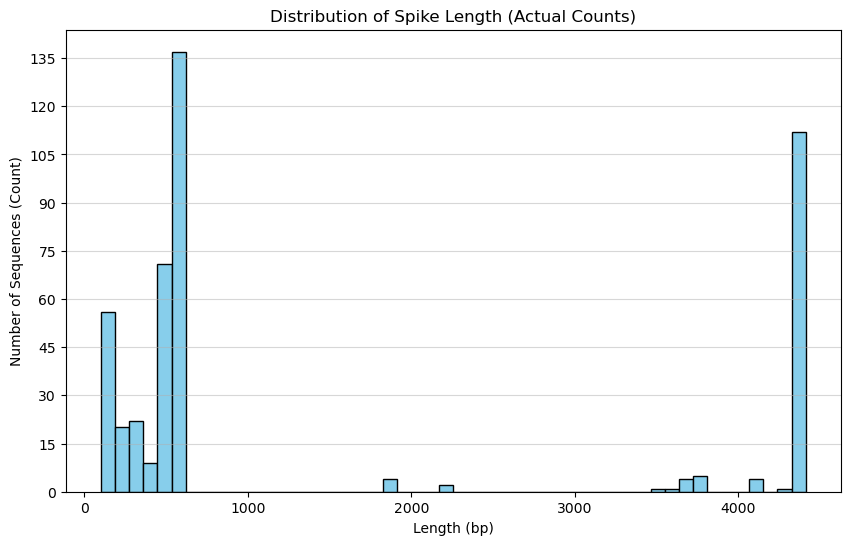

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# 1. データの統計量を表示
print(spike_prefinal_combibed['Spike_Length'].describe())

# 2. ヒストグラムを描画
plt.figure(figsize=(10, 6))
counts, bins, patches = plt.hist(spike_prefinal_combibed['Spike_Length'], bins=50, color='skyblue', edgecolor='black')

# 3. Y軸を整数（件数）として強制的に表示させる設定
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.title('Distribution of Spike Length (Actual Counts)')
plt.xlabel('Length (bp)')
plt.ylabel('Number of Sequences (Count)') # ラベルを「件数」に変更
plt.grid(axis='y', alpha=0.5)

# (オプション) 各ビンの正確な件数をコンソールに出力して確認
print("\n--- 各ビンの件数 ---")
for i in range(len(counts)):
    if counts[i] > 0:
        print(f"{int(bins[i])} bp - {int(bins[i+1])} bp: {int(counts[i])} sequences")

plt.show()

In [37]:
spike_al_meta = spike_prefinal_combibed.drop(columns=['seq'])
spike_al_meta

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...
444,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI
445,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,186,NaN,USA,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI
446,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,360,NaN,Indonesia,Felis catus,ascites,NaN,04-FEB-2024,NCBI
447,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI


In [43]:
spike_al_meta.to_csv('FCoV1_S_all_seq_final_meta_20260306.tsv', sep='\t', index=False)

配列にCCCCCCCC....が含まれていてアライメントから除く
JQ304385.1
metaもマニュアルで更新済み。